# Entrenamiento del modelo de clasificación de actividades humanas

## 1. Objetivo

Entrenar un modelo de aprendizaje automático que permita identificar seis
actividades humanas mediante señales de aceleración y velocidad angular.

Se utilizará un árbol de decisión debido a su interpretabilidad, bajo costo
computacional y facilidad de implementación en un ESP32.

Cada ventana contiene 128 muestras de seis señales inerciales. De estas señales
se extraerán 30 características estadísticas que servirán como entrada del modelo.

## 2. Metodología

1. Cargar los conjuntos originales de entrenamiento y prueba.
2. Extraer 30 características estadísticas de cada ventana.
3. Entrenar y comparar árboles de decisión con diferentes hiperparámetros.
4. Seleccionar el modelo mediante validación cruzada agrupada por sujetos.
5. Evaluar el modelo final utilizando el conjunto de prueba independiente.
6. Guardar el modelo entrenado para su posterior implementación en ESP32.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
# Cargar el dataset

# Buscar el dataset
rutas_base = [Path.cwd(), *list(Path.cwd().parents)[:3]]

candidatos = [
    base / subruta
    for base in rutas_base
    for subruta in [
        "humanActivityRecognitionUsingSmartPhones/UCI HAR Dataset",
        "UCI HAR Dataset"
    ]
]

DATASET = next(
    (ruta.resolve() for ruta in candidatos
     if (ruta / "activity_labels.txt").is_file()),
    None
)

if DATASET is None:
    raise FileNotFoundError("No se encontró el dataset UCI HAR")

CANALES = [
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z"
]

def cargar_datos(split):
    carpeta = DATASET / split

    X = np.stack([
        np.loadtxt(
            carpeta / "Inertial Signals" / f"{canal}_{split}.txt",
            dtype=np.float32
        )
        for canal in CANALES
    ], axis=-1)

    y = np.loadtxt(
        carpeta / f"y_{split}.txt",
        dtype=np.int64
    )

    sujetos = np.loadtxt(
        carpeta / f"subject_{split}.txt",
        dtype=np.int64
    )

    return X, y, sujetos


X_train, y_train, sujetos_train = cargar_datos("train")
X_test, y_test, sujetos_test = cargar_datos("test")

etiquetas = pd.read_csv(
    DATASET / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["id", "actividad"]
)

mapa_actividades = etiquetas.set_index("id")["actividad"]

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Sujetos compartidos:",
      np.intersect1d(sujetos_train, sujetos_test))

Entrenamiento: (7352, 128, 6)
Prueba: (2947, 128, 6)
Sujetos compartidos: []


In [3]:
# Extraccion de características

ESTADISTICAS = ["mean", "std", "min", "max", "rms"]

def extraer_caracteristicas(X):

    media = np.mean(X, axis=1)
    desviacion = np.std(X, axis=1)
    minimo = np.min(X, axis=1)
    maximo = np.max(X, axis=1)
    rms = np.sqrt(np.mean(X**2, axis=1))

    return np.concatenate(
        [media, desviacion, minimo, maximo, rms],
        axis=1
    )


X_train_features = extraer_caracteristicas(X_train)
X_test_features = extraer_caracteristicas(X_test)

nombres_features = [
    f"{estadistica}_{canal}"
    for estadistica in ESTADISTICAS
    for canal in CANALES
]

print("Entrenamiento:", X_train_features.shape)
print("Prueba:", X_test_features.shape)

Entrenamiento: (7352, 30)
Prueba: (2947, 30)


# Entrenamiento y busqueda de hiperparámetros

No seleccionaremos arbitrariamente la profundidad del árbol. Compararemos varios valores y elegiremos el que obtenga mejor rendimiento mediante validación cruzada.

Utilizaremos GroupKFold para que las ventanas de un mismo sujeto nunca aparezcan simultáneamente en los subconjuntos de entrenamiento y validación.

También evaluaremos min_samples_leaf, que controla el número mínimo de ejemplos necesarios en una hoja y ayuda a limitar el sobreajuste.

In [4]:
# Modelo base
arbol = DecisionTreeClassifier(
    random_state=42
)

# Hiperparámetros
parametros = {
    "max_depth": [3, 4, 5, 6, 8, 10],
    "min_samples_leaf": [5, 10, 20]
}

# Validación cruzada agrupada por sujetos
cv = GroupKFold(n_splits=5)

busqueda = GridSearchCV(
    estimator=arbol,
    param_grid=parametros,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

# Entrenamiento
busqueda.fit(
    X_train_features,
    y_train,
    groups=sujetos_train
)

print("Mejores parámetros:", busqueda.best_params_)
print("Mejor F1-macro CV:", busqueda.best_score_)


Mejores parámetros: {'max_depth': 5, 'min_samples_leaf': 20}
Mejor F1-macro CV: 0.8099996699656093


# Comparacion de hiperparametros

Visualizamos como cambia el rendimiento al modificar la profundidad del arbol

,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score,std_test_score
8,5,20,0.868078,0.810000,0.043484
12,8,5,0.941217,0.808391,0.040554
15,10,5,0.964976,0.808103,0.048770
5,4,20,0.839431,0.807687,0.051442
3,4,5,0.839464,0.807474,0.051501
4,4,10,0.839464,0.807474,0.051501
6,5,5,0.869856,0.804198,0.042883
7,5,10,0.869236,0.803891,0.043126
14,8,20,0.927241,0.803216,0.051044
13,8,10,0.937425,0.803190,0.043837


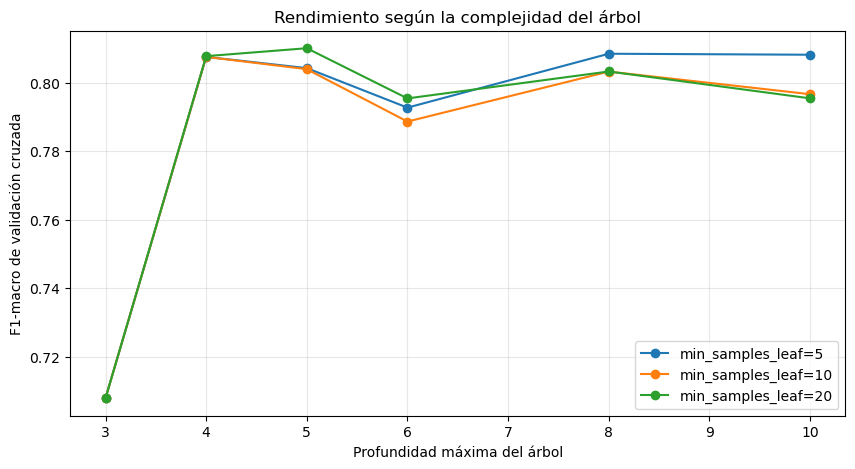

In [5]:
resultados_cv = pd.DataFrame(busqueda.cv_results_)

tabla_resultados = resultados_cv[
    [
        "param_max_depth",
        "param_min_samples_leaf",
        "mean_train_score",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

tabla_resultados = tabla_resultados.sort_values(
    "mean_test_score",
    ascending=False
)

display(tabla_resultados)

plt.figure(figsize=(10, 5))

for min_leaf in parametros["min_samples_leaf"]:

    datos = resultados_cv[
        resultados_cv["param_min_samples_leaf"] == min_leaf
    ].sort_values("param_max_depth")

    plt.plot(
        datos["param_max_depth"],
        datos["mean_test_score"],
        marker="o",
        label=f"min_samples_leaf={min_leaf}"
    )

plt.xlabel("Profundidad máxima del árbol")
plt.ylabel("F1-macro de validación cruzada")
plt.title("Rendimiento según la complejidad del árbol")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Evaluacion Final con el conjunto de prueba

In [6]:
mejor_modelo = busqueda.best_estimator_

# Predicciones sobre el conjunto de prueba
y_pred = mejor_modelo.predict(X_test_features)

accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy: {accuracy:.4f}")
print(f"F1-macro: {f1_macro:.4f}")

print("\nReporte de clasificación:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=etiquetas["id"].tolist(),
        target_names=etiquetas["actividad"].tolist(),
        digits=4
    )
)

Accuracy: 0.7760
F1-macro: 0.7715

Reporte de clasificación:

                    precision    recall  f1-score   support

           WALKING     0.5677    0.6593    0.6101       496
  WALKING_UPSTAIRS     0.5978    0.6815    0.6369       471
WALKING_DOWNSTAIRS     0.9239    0.6071    0.7328       420
           SITTING     0.9156    0.7067    0.7977       491
          STANDING     0.7788    0.9398    0.8518       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.7760      2947
         macro avg     0.7973    0.7658    0.7715      2947
      weighted avg     0.7981    0.7760    0.7778      2947



# Matriz de confusion

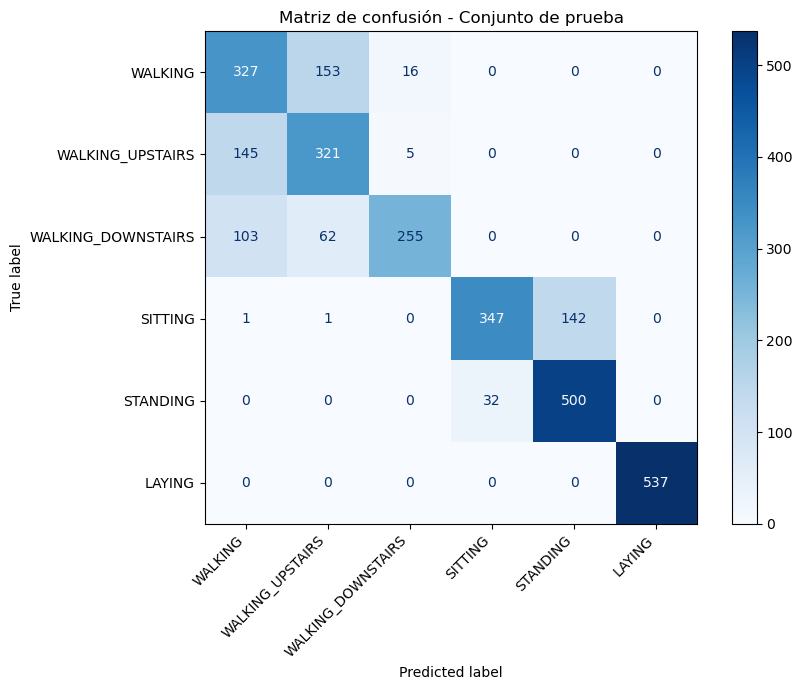

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=etiquetas["id"].tolist(),
    display_labels=etiquetas["actividad"].tolist(),
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matriz de confusión - Conjunto de prueba")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Importancia de las caracteristicas

Cuales de las 30 caracteristicas utiliza mas el arbol

,Importancia
mean_total_acc_x,0.306061
std_total_acc_x,0.272093
mean_total_acc_y,0.240410
max_total_acc_x,0.135132
mean_body_gyro_x,0.024556
max_body_gyro_x,0.009431
min_body_gyro_x,0.008704
rms_total_acc_z,0.002067
min_total_acc_z,0.001357
std_body_gyro_z,0.000188


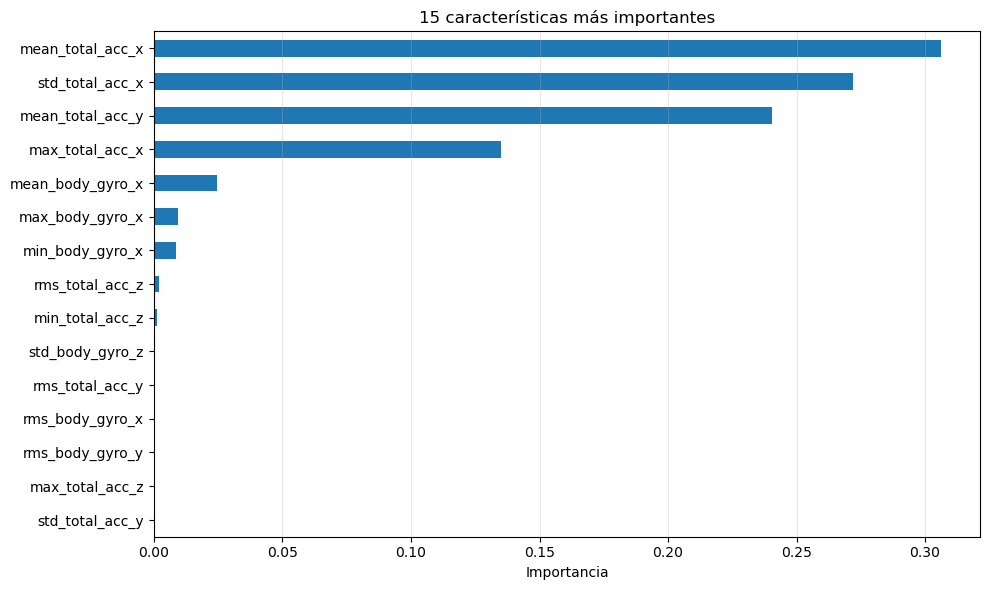

Profundidad: 5
Número de nodos: 33
Número de hojas: 17


In [8]:
importancias = pd.Series(
    mejor_modelo.feature_importances_,
    index=nombres_features
).sort_values(ascending=False)

display(importancias.to_frame("Importancia"))

plt.figure(figsize=(10, 6))

importancias.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Importancia")
plt.title("15 características más importantes")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Profundidad:", mejor_modelo.get_depth())
print("Número de nodos:", mejor_modelo.tree_.node_count)
print("Número de hojas:", mejor_modelo.get_n_leaves())

# Probar una sola ventana

Seleccionaremos una ventana de prueba, calcularemos sus características y ejecutaremos una sola inferencia.

In [9]:
# Seleccionar una ventana del conjunto de prueba
indice = 0

ventana = X_test[indice]

# Extraer sus 30 características
caracteristicas = extraer_caracteristicas(
    ventana[np.newaxis, :, :]
)

# Ejecutar una inferencia
prediccion = mejor_modelo.predict(caracteristicas)[0]

etiqueta_real = y_test[indice]

print("Ventana:", indice)
print("Sujeto:", sujetos_test[indice])

print("Actividad real:",
      mapa_actividades.loc[etiqueta_real])

print("Actividad predicha:",
      mapa_actividades.loc[prediccion])

print("¿Predicción correcta?",
      prediccion == etiqueta_real)

Ventana: 0
Sujeto: 2
Actividad real: STANDING
Actividad predicha: STANDING
¿Predicción correcta? True


# Guardar el modelo

In [10]:
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "modelo": mejor_modelo,
        "features": nombres_features,
        "canales": CANALES,
        "actividades": mapa_actividades.to_dict()
    },
    MODELS_DIR / "modelo_har.joblib"
)

print("Modelo guardado en:")
print(MODELS_DIR / "modelo_har.joblib")

Modelo guardado en:
/Users/jrgels/Documents/Maestria/TERCER SEMESTRE/TinyML/Proyecto 1/humanActivityRecognitionUsingSmartPhones/models/modelo_har.joblib


In [11]:
print("Mejores hiperparámetros:")
print(busqueda.best_params_)

print("\nComplejidad del modelo:")
print("Profundidad:", mejor_modelo.get_depth())
print("Número de nodos:", mejor_modelo.tree_.node_count)
print("Número de hojas:", mejor_modelo.get_n_leaves())

print("\nCaracterísticas utilizadas:",
      np.sum(mejor_modelo.feature_importances_ > 0))

Mejores hiperparámetros:
{'max_depth': 5, 'min_samples_leaf': 20}

Complejidad del modelo:
Profundidad: 5
Número de nodos: 33
Número de hojas: 17

Características utilizadas: 10


## 3. Exportación del modelo a C++

El modelo seleccionado tiene una profundidad máxima de 5, 33 nodos y 17 hojas.

Para implementarlo en un ESP32, se convertirá la estructura del árbol
a instrucciones condicionales en C++.

Esta representación conserva las reglas y umbrales aprendidos durante
el entrenamiento, sin necesidad de utilizar bibliotecas externas de
aprendizaje automático.

In [12]:
# Exportación del árbol de decisión a C++

from pathlib import Path
import numpy as np

arbol = mejor_modelo.tree_

assert mejor_modelo.n_features_in_ == len(nombres_features)

def exportar_nodo(nodo, nivel=1):
    """
    Convierte recursivamente cada nodo del árbol
    a instrucciones if/else de C++.
    """

    tab = "    " * nivel

    izquierdo = int(arbol.children_left[nodo])
    derecho = int(arbol.children_right[nodo])

    # Nodo hoja: devolver la clase predicha
    if izquierdo == derecho:

        indice_clase = int(
            np.argmax(arbol.value[nodo, 0, :])
        )

        clase = int(mejor_modelo.classes_[indice_clase])

        return (
            f"{tab}return {clase}; "
            f"// {mapa_actividades.loc[clase]}"
        )

    # Nodo de decisión
    feature = int(arbol.feature[nodo])
    umbral = format(
        float(arbol.threshold[nodo]), ".17g"
    )

    return (
        f"{tab}// {nombres_features[feature]}\n"
        f"{tab}if (features[{feature}] <= {umbral}) {{\n"
        f"{exportar_nodo(izquierdo, nivel + 1)}\n"
        f"{tab}}} else {{\n"
        f"{exportar_nodo(derecho, nivel + 1)}\n"
        f"{tab}}}"
    )


# Generar nombres de actividades
casos = "\n".join(
    f'        case {int(clase)}: return '
    f'"{mapa_actividades.loc[int(clase)]}";'
    for clase in mejor_modelo.classes_
)

# Construir archivo C++
codigo_cpp = (
    "#pragma once\n"
    "#include <stdint.h>\n\n"
    "namespace har {\n\n"
    f"constexpr int NUM_FEATURES = {len(nombres_features)};\n\n"
    "inline int predict(const float features[NUM_FEATURES]) {\n"
    + exportar_nodo(0)
    + "\n}\n\n"
    "inline const char* activityName(int clase) {\n"
    "    switch (clase) {\n"
    + casos
    + '\n        default: return "UNKNOWN";\n'
    "    }\n"
    "}\n\n"
    "} // namespace har\n"
)

# Guardar el archivo
MODELS_DIR.mkdir(parents=True, exist_ok=True)

ruta_cpp = MODELS_DIR / "decision_tree.h"
ruta_cpp.write_text(codigo_cpp, encoding="utf-8")

print("Archivo generado:", ruta_cpp)
print("Nodos exportados:", arbol.node_count)
print("Hojas:", mejor_modelo.get_n_leaves())
print("\nVista previa:\n")
print("\n".join(codigo_cpp.splitlines()[:25]))

Archivo generado: /Users/jrgels/Documents/Maestria/TERCER SEMESTRE/TinyML/Proyecto 1/humanActivityRecognitionUsingSmartPhones/models/decision_tree.h
Nodos exportados: 33
Hojas: 17

Vista previa:

#pragma once
#include <stdint.h>

namespace har {

constexpr int NUM_FEATURES = 30;

inline int predict(const float features[NUM_FEATURES]) {
    // mean_total_acc_x
    if (features[0] <= 0.3867424875497818) {
        return 6; // LAYING
    } else {
        // std_total_acc_x
        if (features[6] <= 0.093192871659994125) {
            // mean_total_acc_y
            if (features[1] <= -0.066491559147834778) {
                // min_body_gyro_x
                if (features[15] <= -0.0094097941182553768) {
                    // min_total_acc_z
                    if (features[14] <= -0.081149674952030182) {
                        return 5; // STANDING
                    } else {
                        return 5; // STANDING
                    }
                } else {


# 3. Implementar las caracteristicas en C++

El ESP32 recibira los 768 valores originales de la ventana, no las 30 caracteristicas ya calculadas.

Se hara en C++ las mismas estadisticas que usamos en Python

In [13]:
codigo_features = r"""
#pragma once
#include <math.h>

namespace har {

constexpr int WINDOW_SIZE = 128;
constexpr int CHANNELS = 6;

inline void extractFeatures(
    const float samples[WINDOW_SIZE][CHANNELS],
    float features[30]
) {
    for (int j = 0; j < CHANNELS; j++) {

        float suma = 0.0f;
        float sumaCuadrados = 0.0f;

        float minimo = samples[0][j];
        float maximo = samples[0][j];

        // Primera pasada: media, mínimo, máximo y RMS
        for (int i = 0; i < WINDOW_SIZE; i++) {

            float x = samples[i][j];

            suma += x;
            sumaCuadrados += x * x;

            if (x < minimo) minimo = x;
            if (x > maximo) maximo = x;
        }

        float media = suma / WINDOW_SIZE;

        // Segunda pasada: varianza
        float sumaDesviaciones = 0.0f;

        for (int i = 0; i < WINDOW_SIZE; i++) {

            float diferencia = samples[i][j] - media;

            sumaDesviaciones += diferencia * diferencia;
        }

        float desviacion = sqrtf(
            sumaDesviaciones / WINDOW_SIZE
        );

        float rms = sqrtf(
            sumaCuadrados / WINDOW_SIZE
        );

        // Mantener el orden usado durante entrenamiento
        features[j]      = media;
        features[6 + j]  = desviacion;
        features[12 + j] = minimo;
        features[18 + j] = maximo;
        features[24 + j] = rms;
    }
}

} // namespace har
"""

ruta_features = MODELS_DIR / "imu_features.h"

ruta_features.write_text(
    codigo_features,
    encoding="utf-8"
)

print("Archivo generado:", ruta_features)

Archivo generado: /Users/jrgels/Documents/Maestria/TERCER SEMESTRE/TinyML/Proyecto 1/humanActivityRecognitionUsingSmartPhones/models/imu_features.h


# Comprobar que C++ y Pythyon coinciden en la predicción

Ejecutar las mismas ventanas de prueba tanto en Python como en el código C++ generado y comparar sus predicciones

In [14]:
import subprocess
import tempfile
import shutil

# Programa C++ de verificación
codigo_prueba = r"""
#include <iostream>
#include "decision_tree.h"
#include "imu_features.h"

int main() {

    float ventana[128][6];
    float features[30];

    // Leer ventanas completas desde entrada estándar
    while (std::cin >> ventana[0][0]) {

        for (int i = 1; i < 128 * 6; i++) {

            if (!(std::cin >> ventana[i / 6][i % 6])) {
                return 1;
            }
        }

        har::extractFeatures(ventana, features);

        int prediccion = har::predict(features);

        std::cout << prediccion << '\n';
    }

    return 0;
}
"""

compilador = (
    shutil.which("clang++")
    or shutil.which("g++")
)

if compilador is None:
    raise RuntimeError(
        "No se encontró clang++ ni g++. "
        "Es necesario instalar un compilador C++."
    )

# Número de ventanas que verificaremos
N_PRUEBAS = 100

# Preparar exactamente las muestras originales
datos_entrada = ""

for ventana in X_test[:N_PRUEBAS]:
    valores = ventana.reshape(-1)

    datos_entrada += " ".join(
        format(float(valor), ".9g")
        for valor in valores
    ) + "\n"

with tempfile.TemporaryDirectory() as temp:

    temp = Path(temp)

    archivo_prueba = temp / "verificar.cpp"
    ejecutable = temp / "verificar"

    archivo_prueba.write_text(codigo_prueba)

    # Compilar código C++
    subprocess.run(
        [
            compilador,
            "-std=c++11",
            "-O2",
            "-I", str(MODELS_DIR),
            str(archivo_prueba),
            "-o", str(ejecutable)
        ],
        check=True
    )

    # Ejecutar inferencias en C++
    resultado = subprocess.run(
        [str(ejecutable)],
        input=datos_entrada,
        capture_output=True,
        text=True,
        check=True
    )

# Predicciones del código C++
pred_cpp = np.fromstring(
    resultado.stdout,
    sep=" ",
    dtype=np.int64
)

# Predicciones del modelo original en Python
pred_python = mejor_modelo.predict(
    X_test_features[:N_PRUEBAS]
)

assert len(pred_cpp) == N_PRUEBAS

# Comparación
coincidencias = np.sum(pred_cpp == pred_python)

print("Ventanas verificadas:", N_PRUEBAS)
print("Predicciones coincidentes:", coincidencias)

print(
    f"Coincidencia Python/C++: "
    f"{coincidencias / N_PRUEBAS:.2%}"
)

diferencias = np.flatnonzero(
    pred_cpp != pred_python
)

print("Índices con diferencias:", diferencias)

Ventanas verificadas: 100
Predicciones coincidentes: 100
Coincidencia Python/C++: 100.00%
Índices con diferencias: []
